# Epoch 0: pretrained CordsNet-R8 vs monkey N

Frozen pretrained model, val split (1,854 images, batches of 64 from one day). CKA per model layer, brain area and 10 ms bin.

- CKA_0: usual linear CKA (training-loss form), mean over batches
- CKA_S, CKA_C: corrected estimators (Chun et al. 2025), H values pooled over batches
- NaN = undefined (deep layers in the first bins: all images still give the same spontaneous activity)

Inputs: `Round1/outputs/epoch0_pretrained/results.npz` (copied from Torch), raw monkey N npz files in `~/Desktop/neural_data` (Figure 3 only).

In [1]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

warnings.filterwarnings("ignore", category=RuntimeWarning)   # nanmean over all-NaN bins

ROUND1 = Path("~/Desktop/DynVision/CordsNet/Round1").expanduser()
RESULTS = ROUND1 / "outputs" / "epoch0_pretrained" / "results.npz"
NEURAL = Path("~/Desktop/neural_data").expanduser()

r = np.load(RESULTS)
layers, areas, ests = [[str(x) for x in r[k]] for k in ("layers", "areas", "estimators")]
t_ms = r["bin_start_ms"] + 5                    # bin centers
cka_batch = r["cka_batch"]                      # (batch, layer, area, bin, estimator)
days = r["batch_day"]

# one table (layer, area, bin, estimator): CKA_0 mean over batches, CKA_S / CKA_C pooled
cka = np.stack([np.nanmean(cka_batch[..., 0], axis=0), r["cka_pooled"][..., 1], r["cka_pooled"][..., 2]], axis=-1)

# response windows: from response onset to 200 ms (monkey N time courses)
window = {"V1": np.arange(3, 20), "V4": np.arange(3, 20), "IT": np.arange(7, 20)}

est_color = {"CKA_0": "#2a78d6", "CKA_S": "#eb6834", "CKA_C": "#1baf7a"}
area_color = {"V1": "#2a78d6", "V4": "#eb6834", "IT": "#1baf7a"}
day_color = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
layer_color = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#184f95", "#0d366b"]

print(f"{cka_batch.shape[0]} batches, days {sorted(set(days.tolist()))}")
print("layers:", layers, "| areas:", areas, "| estimators:", ests)

27 batches, days [1, 2, 3, 4]
layers: ['layer1', 'layer2', 'layer3', 'layer4', 'layer5', 'layer6', 'layer7', 'layer8'] | areas: ['V1', 'V4', 'IT'] | estimators: ['CKA_0', 'CKA_S', 'CKA_C']


## 1. Which layer matches each area?

CKA averaged over bins, for every layer. Top: all 20 bins. Bottom: response window only (V1, V4 30-200 ms; IT 70-200 ms).
Error bars: SEM across batches (CKA_0 only).

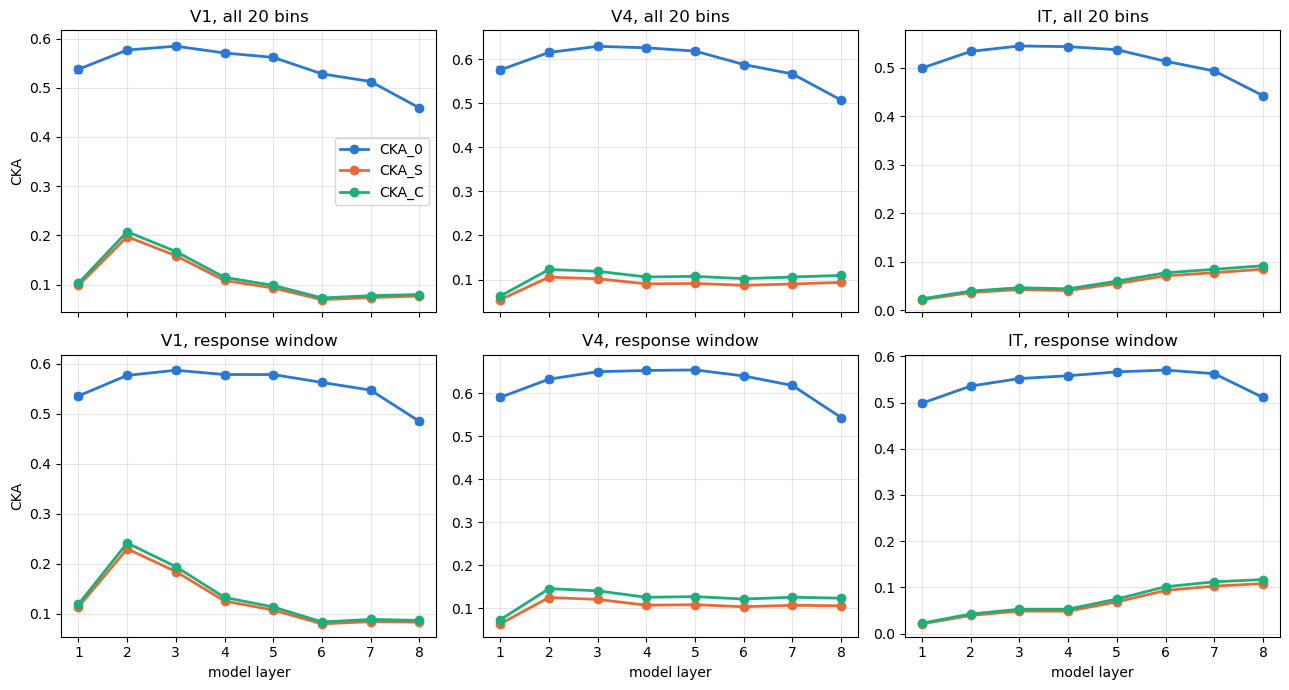

Response window, mean CKA per layer (layer1 ... layer8):
  V1 CKA_0: best layer3   0.536  0.577  0.587  0.579  0.579  0.563  0.548  0.485
  V1 CKA_S: best layer2   0.114  0.230  0.184  0.125  0.107  0.080  0.084  0.083
  V1 CKA_C: best layer2   0.119  0.242  0.194  0.133  0.113  0.084  0.089  0.087
  V4 CKA_0: best layer5   0.591  0.633  0.651  0.654  0.655  0.641  0.619  0.544
  V4 CKA_S: best layer2   0.063  0.125  0.120  0.107  0.108  0.103  0.106  0.105
  V4 CKA_C: best layer2   0.073  0.145  0.140  0.125  0.127  0.121  0.125  0.123
  IT CKA_0: best layer6   0.499  0.536  0.552  0.558  0.566  0.570  0.563  0.511
  IT CKA_S: best layer8   0.021  0.039  0.049  0.049  0.069  0.093  0.103  0.108
  IT CKA_C: best layer8   0.023  0.042  0.053  0.053  0.075  0.101  0.112  0.117


In [2]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for row, label in enumerate(["all 20 bins", "response window"]):
    for j, area in enumerate(areas):
        ax = axes[row, j]
        b = np.arange(20) if row == 0 else window[area]
        for e, est in enumerate(ests):
            ax.plot(range(1, 9), np.nanmean(cka[:, j, b, e], axis=1), "o-", color=est_color[est], lw=2, ms=6, label=est)
        per_batch = np.nanmean(cka_batch[:, :, j, b, 0], axis=2)                 # (batch, layer)
        sem = np.nanstd(per_batch, axis=0) / np.sqrt(np.isfinite(per_batch).sum(axis=0))
        ax.errorbar(range(1, 9), np.nanmean(per_batch, axis=0), yerr=sem, fmt="none", ecolor=est_color["CKA_0"], capsize=3)
        ax.set_title(f"{area}, {label}")
        ax.set_xticks(range(1, 9))
        ax.grid(alpha=0.3)
    axes[row, 0].set_ylabel("CKA")
for ax in axes[1]:
    ax.set_xlabel("model layer")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

print("Response window, mean CKA per layer (layer1 ... layer8):")
for j, area in enumerate(areas):
    for e, est in enumerate(ests):
        y = np.nanmean(cka[:, j, window[area], e], axis=1)
        print(f"  {area} {est}: best {layers[int(np.nanargmax(y))]}   " + "  ".join(f"{v:.3f}" for v in y))

## 2. CKA over time

CKA_0 per bin, one line per layer (light = layer1, dark = layer8). Gray: response window.

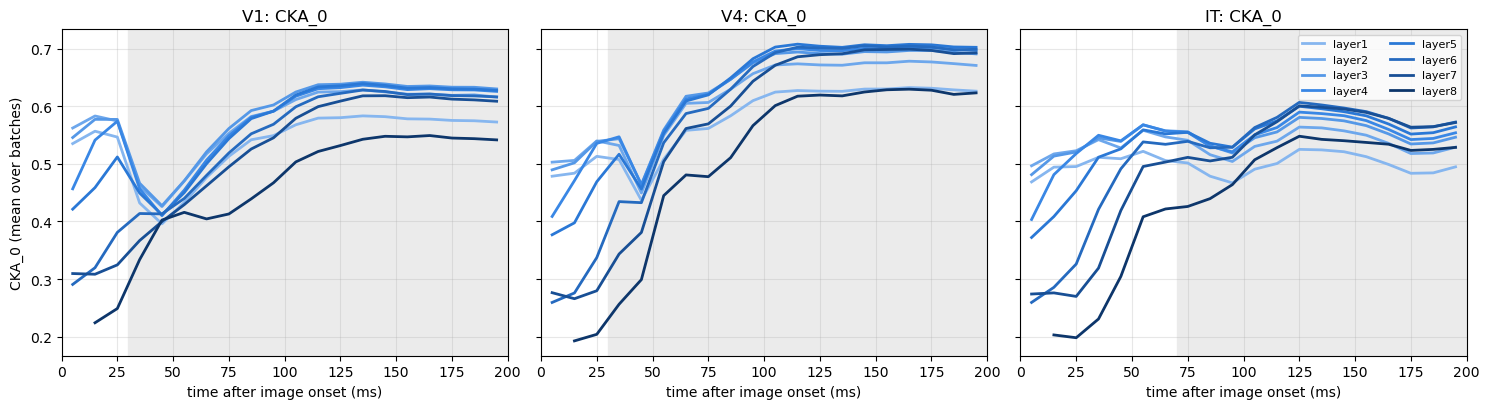

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for j, area in enumerate(areas):
    ax = axes[j]
    ax.axvspan(window[area][0] * 10, 200, color="0.92", zorder=0)
    for i, layer in enumerate(layers):
        ax.plot(t_ms, cka[i, j, :, 0], "-", color=layer_color[i], lw=2, label=layer)
    ax.set(title=f"{area}: CKA_0", xlabel="time after image onset (ms)", xlim=(0, 200))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("CKA_0 (mean over batches)")
axes[-1].legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 3. Response timing: model layers vs brain areas

Mean activity over time, scaled so that the first bin = 0 and the peak = 1.
Model: mean recorded activity of each layer (val images). Brain: mean MUA over all trials and electrodes of all 4 days (V1 without channels 320-383).

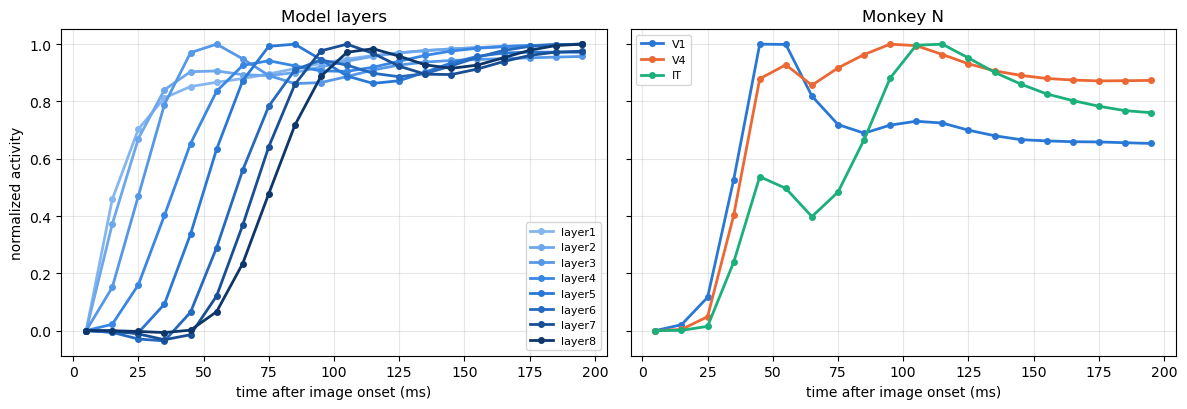

Time to half of the peak (bin center, ms):
  layer1: 25
  layer2: 25
  layer3: 35
  layer4: 45
  layer5: 55
  layer6: 65
  layer7: 75
  layer8: 85
  V1: 35
  V4: 45
  IT: 45


In [4]:
neural_tc = {}
for area in areas:
    total, n = np.zeros(20), 0
    for f in sorted(NEURAL.rglob(f"monkeyN_day*_{area}_binned.npz")):
        mua = np.load(f)["binned_mua"]
        if area == "V1":
            mua = np.delete(mua, np.arange(320, 384), axis=2)
        total += mua.sum(axis=(1, 2))
        n += mua.shape[1] * mua.shape[2]
    neural_tc[area] = total / n

model_tc = r["model_timecourse"]                                           # (layer, bin)
model_n = (model_tc - model_tc[:, :1]) / (model_tc.max(axis=1, keepdims=True) - model_tc[:, :1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for i, layer in enumerate(layers):
    axes[0].plot(t_ms, model_n[i], "o-", color=layer_color[i], lw=2, ms=4, label=layer)
for area in areas:
    c = neural_tc[area]
    axes[1].plot(t_ms, (c - c[0]) / (c.max() - c[0]), "o-", color=area_color[area], lw=2, ms=4, label=area)
axes[0].set(title="Model layers", xlabel="time after image onset (ms)", ylabel="normalized activity")
axes[1].set(title="Monkey N", xlabel="time after image onset (ms)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Time to half of the peak (bin center, ms):")
for i, layer in enumerate(layers):
    print(f"  {layer}: {t_ms[np.argmax(model_n[i] >= 0.5)]}")
for area in areas:
    c = neural_tc[area]
    print(f"  {area}: {t_ms[np.argmax((c - c[0]) / (c.max() - c[0]) >= 0.5)]}")

## 4. Three CKA estimators

Best layer per area (highest CKA_0 in the response window), CKA over time with each estimator.

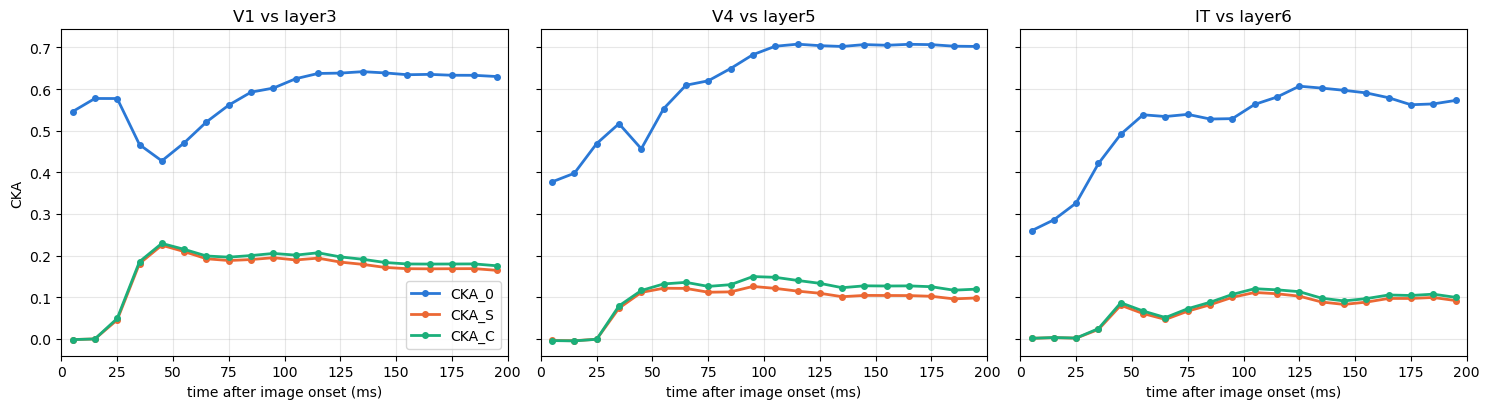

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for j, area in enumerate(areas):
    i = int(np.nanargmax(np.nanmean(cka[:, j, window[area], 0], axis=1)))
    for e, est in enumerate(ests):
        axes[j].plot(t_ms, cka[i, j, :, e], "o-", color=est_color[est], lw=2, ms=4, label=est)
    axes[j].set(title=f"{area} vs {layers[i]}", xlabel="time after image onset (ms)", xlim=(0, 200))
    axes[j].grid(alpha=0.3)
axes[0].set_ylabel("CKA")
axes[0].legend()
plt.tight_layout()
plt.show()

**Per bin CKA after image onset:**
- CordsNet model image onset begins the 200ms (0 to 100ms idle steps, 100 time steps)
- CKA computed using validation set (1854 images, 64 images per batch, on the same day)
- 0-25ms, CKA_S and CKA_C = 0, which is what we want to see
    - Because from figure 3, right, neural activity begins after 25ms, so before 25ms it's just random noise. On the model side however there is already systematic processing of image contents; random vs. systematic, CKA near 0 is expected.

- See how CKA_0, from 0-25ms has high CKA: due to the diagonal impact!
- CKA_0 is also misleading, if we look at the left most figure, at around 45ms where CKA_S and CKA_C are the highest, CKA_0 is the lowest.
- **We should go with CKA_S**

## 5. Check: consistency across recording days

Best layer per area, CKA_0 over time, averaged over the batches of each day.

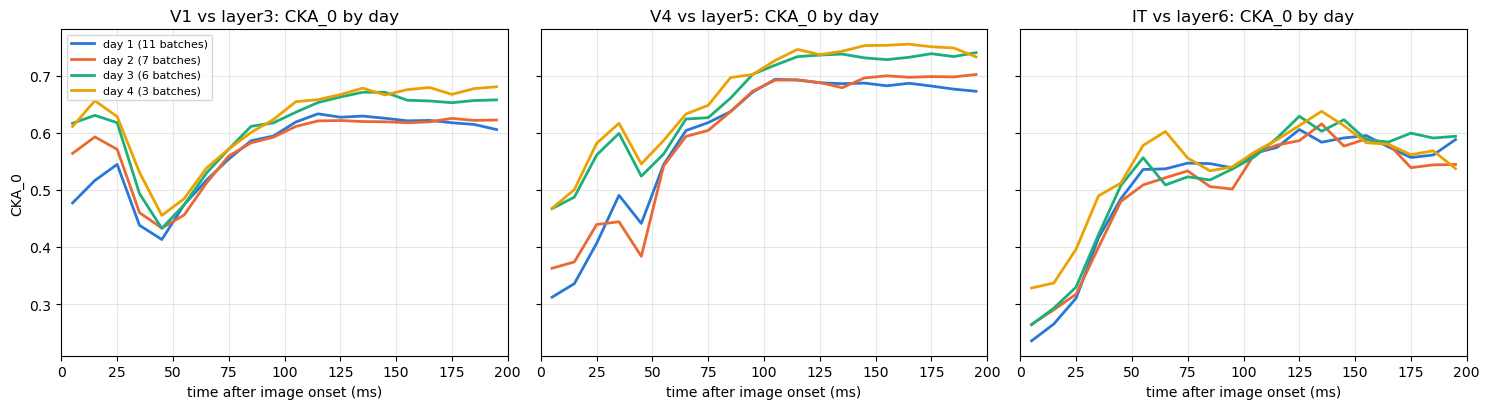

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for j, area in enumerate(areas):
    i = int(np.nanargmax(np.nanmean(cka[:, j, window[area], 0], axis=1)))
    for k, d in enumerate(sorted(set(days.tolist()))):
        sel = days == d
        axes[j].plot(t_ms, np.nanmean(cka_batch[sel, i, j, :, 0], axis=0), "-", color=day_color[k], lw=2,
                     label=f"day {d} ({sel.sum()} batches)")
    axes[j].set(title=f"{area} vs {layers[i]}: CKA_0 by day", xlabel="time after image onset (ms)", xlim=(0, 200))
    axes[j].grid(alpha=0.3)
axes[0].set_ylabel("CKA_0")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()